In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.patches as mpatches
import os
import pandas as pd
import networkx as nx
import datetime
import random
import plotly.express as px
import seaborn as sns
from networkx.convert_matrix import from_numpy_array
from scipy.stats import ttest_ind

from hypnetperturb.utils import *
from hypnetperturb.embedding.coalescent_embedding import *
from hypnetperturb.embedding.distance import *
from hypnetperturb.visualization import *
from hypnetperturb.metrics.kNdist_score import *
from hypnetperturb.perturb_network import *
from hypnetperturb.generate_network import *

## 0) Plot original graph and perturbation

- used for image in poster LANET

In [28]:
 # Embedding parameters 
embedding_parameters_dict = {
'pre_weight':True,  
'binarize':True,
'dim_red_method':'ISOMAP',   
'eq_adj':True, 
'eta_r':0.1,
'beta_r':0.8,
'weight_r':False,
'res_dict':False
}

In [29]:
## PARS
N = 20 #number of nodes
kl = 8 #k lattice
pr = 0.1 #p rewiring
mag= 20/100
k = 3
node_colors = np.array(N*['#545454'])
node_sizes =  np.array(N*[0.1])

## Original graph generation and embedding
G = nx.watts_strogatz_graph(N,kl,pr)
Y_G = coalescent_embedding_2D(G, **embedding_parameters_dict)

In [30]:
## Pick most central node (for viz purposes)

r_G = np.sqrt(Y_G[:,0]**2+Y_G[:,1]**2)
ind = np.argsort(r_G)[0] #the second most central actually
ind = np.argsort(r_G)[19]
# find its nearest points in the original graph embedding
D_matrix = hyp_dist_matrix(Y_G,Y_G)
np.fill_diagonal(D_matrix,np.inf)
ind_kN = k_argmin(D_matrix[:,ind],k)
#ind_kN = np.setdiff1d(k_argmin(D_matrix[:,ind_most_central],k+1),ind_most_central)
edgelist = np.array([[ind,ind_kN[i]] for i in range(len(ind_kN))])
edgelist_colors = np.array(len(edgelist)*['#282828'])
# color them
node_colors[ind]='#0F0F0F'
node_colors[ind_kN[0]]= '#0000EE'
edgelist_colors[0]='#0000EE'
node_colors[ind_kN[1]]='#DC143C'
edgelist_colors[1]='#DC143C'
node_colors[ind_kN[2]]='#228B22'
edgelist_colors[2]='#228B22'
#node_colors[ind_kN[3]]='#473C8B'
#edgelist_colors[3]='#6959CD

In [31]:
## Plot
Y_G = native_to_unitnative(Y_G)

Pdisk_G = plot_Pdisk_embedding(Y_G, node_colors=node_colors, edgelist=edgelist, edgelist_colors=edgelist_colors, sizes=node_sizes)
#Pdisk_G.save_svg('/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/media_draw/Pdisk-%iNHD-WS-o.svg'%(k))

## Perturbed graph generation and embedding
G_p, nodes_p_dict = perturbation_disconnection_NT(G,mag,1,target=[ind]) 
Y_G_p = coalescent_embedding_2D(G_p, **embedding_parameters_dict)
Y_G_p = native_to_unitnative(Y_G_p)
Pdisk_G_p = plot_Pdisk_embedding(Y_G_p, node_colors=node_colors, edgelist=edgelist, edgelist_colors=edgelist_colors, sizes=node_sizes)
#Pdisk_G_p.save_svg('/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/media_draw/Pdisk-%iNHD-WS-p%.2f.svg'%(k,mag))

R =  1.0
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1]
R =  1.0
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1]


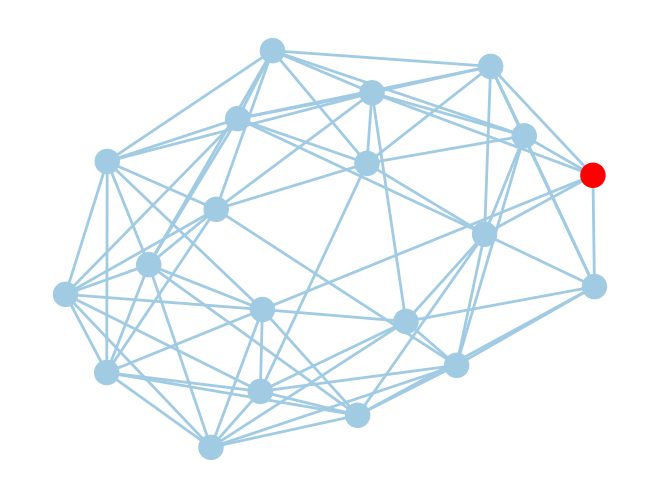

In [32]:
pos = nx.spring_layout(G, seed=63)  # Seed layout for reproducibility
color_nodes = ["#A0CBE2"]*N
color_nodes[nodes_p_dict['nodes_perturbed'][0]]='red'
color_edges = "#A0CBE2"
options = {
    "node_color": color_nodes,
    "edge_color": color_edges,
    "width": 2,
    "edge_cmap": plt.cm.Blues,
    "with_labels": False,
}
nx.draw(G, pos, **options)
plt.show()

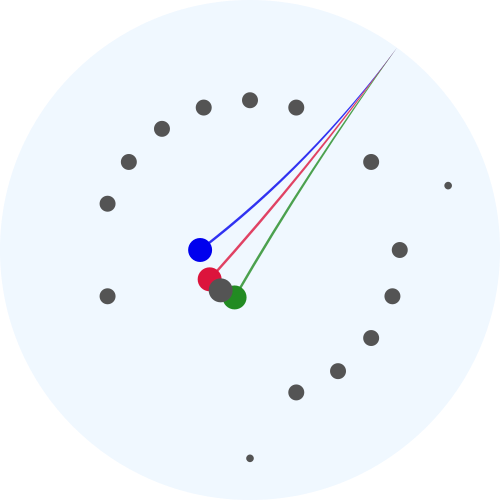

In [33]:
Pdisk_G

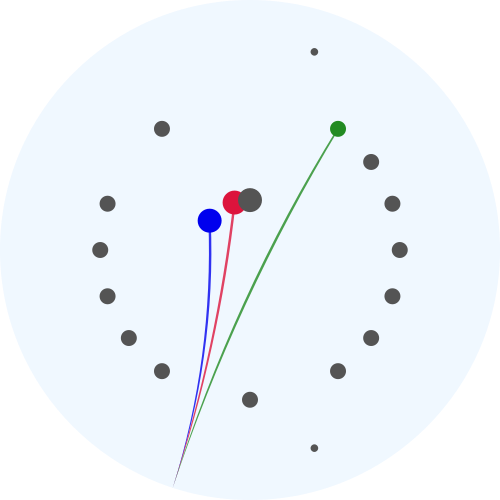

In [34]:
Pdisk_G_p